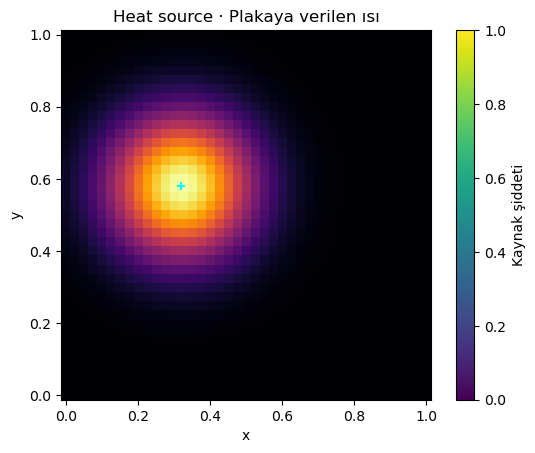

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# [0, 1] × [0, 1] kare plaka üzerinde 41 × 41 nokta.
axis = np.linspace(0, 1, 41)
X, Y = np.meshgrid(axis, axis)

# Isı kaynağının merkezi, şiddeti ve genişliği.
x_source, y_source = 0.32, 0.58
strength = 180.0
sigma = 0.14

distance_squared = (X - x_source)**2 + (Y - y_source)**2
source = strength * np.exp(-distance_squared / (2 * sigma**2))

plt.pcolormesh(X, Y, source, shading="auto", cmap="inferno")
plt.scatter(x_source, y_source, color="cyan", marker="+")
plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Heat source · Plakaya verilen ısı")
plt.colorbar(label="Kaynak şiddeti")
plt.show()

Kaynak maksimumu: 179.771
Maksimum sıcaklık: 24.106


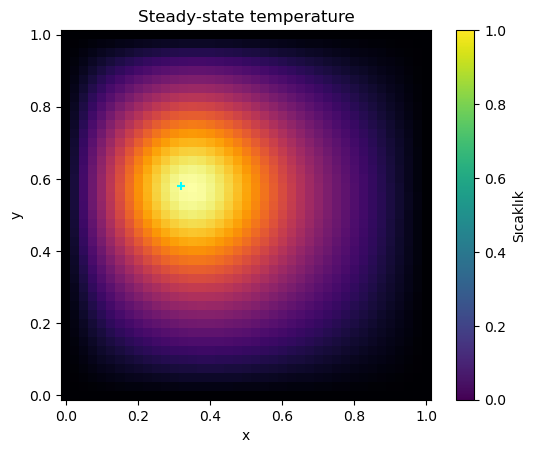

In [2]:
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import spsolve

k = 1.0
boundary_temperature = 20.0
h = axis[1] - axis[0]
n = len(axis) - 2

# Bir eksende komşu katsayıları [-1, 2, -1].
D = diags([-1, 2, -1], offsets=[-1, 0, 1], shape=(n, n))
identity = eye(n)

# x ve y yönlerindeki katkıları topla.
A = (kron(identity, D) + kron(D, identity)).tocsr() / h**2

# Sadece iç noktalar için A @ rise = rhs sistemini çöz.
rhs = (source[1:-1, 1:-1] / k).ravel()
rise = spsolve(A, rhs).reshape(n, n)

# Kenarlara sıfır sıcaklık artışı ekle, sonra 20 dereceyi geri koy.
temperature = boundary_temperature + np.pad(rise, 1)

print("Kaynak maksimumu:", round(float(source.max()), 3))
print(f"Maksimum sıcaklık: {temperature.max():.3f}")

plt.pcolormesh(X, Y, temperature, shading="auto", cmap="inferno")
plt.scatter(x_source, y_source, color="cyan", marker="+")
plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Steady-state temperature")
plt.colorbar(label="Sıcaklık")
plt.show()

In [3]:
from scipy.sparse.linalg import splu

# Aynı grid ve sınır koşulu türü için A'yı bir kez faktörize et.
factor = splu(A.tocsc())

def solve_temperature(xs, ys, strength, k, boundary_temperature):
    distance_squared = (X - xs)**2 + (Y - ys)**2
    heat_source = strength * np.exp(-distance_squared / (2 * sigma**2))

    rhs = (heat_source[1:-1, 1:-1] / k).ravel()
    rise = factor.solve(rhs).reshape(n, n)

    return boundary_temperature + np.pad(rise, 1)

designs = {
    "İlk konum": (0.32, 0.58, 180.0, 1.0, 20.0),
    "Merkez":    (0.50, 0.50, 180.0, 1.0, 20.0),
    "Kenara yakın": (0.18, 0.50, 180.0, 1.0, 20.0),
}

for name, parameters in designs.items():
    field = solve_temperature(*parameters)
    print(f"{name:15s} | maksimum sıcaklık = {field.max():.3f}")

İlk konum       | maksimum sıcaklık = 24.106
Merkez          | maksimum sıcaklık = 24.560
Kenara yakın    | maksimum sıcaklık = 23.186


In [4]:
from scipy.stats import qmc

# Sıra: kaynak x, kaynak y, şiddet, iletkenlik, kenar sıcaklığı.
lower = np.array([0.18, 0.18, 100.0, 0.7, 15.0]) # alt sınır
upper = np.array([0.82, 0.82, 260.0, 1.6, 30.0]) #üst sınır


# Sobol önce [0, 1] aralığında 5 boyutlu noktalar üretir.
sampler = qmc.Sobol(d=5, scramble=True, seed=42)
X_train = sampler.random_base2(m=8)  # 2**8 = 256 tasarım
#qmc.Sobol(...) → Beş boyutlu tasarım uzayına noktaları yayacak örnekleyiciyi kuruyor. 
# d=5, her tasarımın beş parametresi olduğunu söylüyor. scramble=True diziyi rastgeleleştiriyor,
#  seed=42 ise aynı deneyi yeniden üretebilmemizi sağlıyor.
# Solver'a fiziksel değerleri veriyoruz.
train_parameters = qmc.scale(X_train, lower, upper) #qmc.scale(...) → Her sütunu kendi fiziksel aralığına taşıyor.
y_train = np.array([
    solve_temperature(*parameters).max()
    for parameters in train_parameters
])

print("Girdi boyutu:", X_train.shape)
print("Hedef boyutu:", y_train.shape)
print("İlk tasarım:", np.round(train_parameters[0], 3))
print(f"Bu tasarımın maksimum sıcaklığı: {y_train[0]:.3f}")

Girdi boyutu: (256, 5)
Hedef boyutu: (256,)
İlk tasarım: [  0.456   0.701 229.026   0.748  19.469]
Bu tasarımın maksimum sıcaklığı: 26.335


In [5]:
# Eğitimdekiyle aynı 5 parametre için farklı bir Sobol dizisi kur.
test_sampler = qmc.Sobol(d=5, scramble=True, seed=93)

# MLP'ye vereceğimiz 2**7 = 128 normalize test tasarımını üret.
X_test = test_sampler.random_base2(m=7)

# Bu tasarımları solver'ın kullandığı fiziksel aralıklara dönüştür.
test_parameters = qmc.scale(X_test, lower, upper)

# Her test tasarımını PDE solver ile çöz ve maksimum sıcaklığını sakla.
y_test = np.array([
    solve_temperature(*parameters).max()
    for parameters in test_parameters
])

# 128 tasarımın her birinde 5 girdi ve 1 hedef olduğunu kontrol et.
print("Test girdileri:", X_test.shape)  # (128, 5)
print("Test hedefleri:", y_test.shape)  # (128,)

Test girdileri: (128, 5)
Test hedefleri: (128,)


In [6]:
import torch                       # NumPy dizilerini tensor'a çevirmek için.
from torch import nn               # Katmanlar ve loss function burada.

torch.manual_seed(42)              # Aynı başlangıç ağırlıklarını tekrar üretebilmek için.

# 256 tasarım × 5 özellik. float32, modelin ağırlıklarıyla aynı veri tipi.
x_train_tensor = torch.tensor(X_train, dtype=torch.float32)

# Hedefi eğitim ortalaması ve standart sapmasıyla standardize et.
y_mean = y_train.mean()
y_std = y_train.std()
y_scaled = (y_train - y_mean) / y_std

# Her tasarım için bir hedef. [:, None] şekli (256,) → (256, 1) yapar.
y_train_tensor = torch.tensor(y_scaled[:, None], dtype=torch.float32)

model = nn.Sequential(             # Katmanları yazdığımız sırayla uygula.
    nn.Linear(5, 48),              # Beş girdiden 48 ağırlıklı toplam üret.
    nn.SiLU(),                     # Doğrusal olmayan activation function uygula.
    nn.Linear(48, 48),             # İlk katmanın 48 çıktısını yeniden birleştir.
    nn.SiLU(),                     # İkinci katmana da doğrusal olmayanlık ekle.
    nn.Linear(48, 1),              # Her tasarım için tek bir tahmin üret.
)

loss_function = nn.MSELoss()       # Hataların karelerinin ortalamasını al.
optimizer = torch.optim.Adam(model.parameters(), lr=0.004)

model.train()                      # Modeli eğitim moduna al.

for epoch in range(1, 451):        # Her epoch'ta 256 tasarımın tamamını kullan.
    optimizer.zero_grad()          # Önceki epoch'tan kalan gradient'leri temizle.
    prediction = model(x_train_tensor)  # Forward pass. Boyut (256, 1).
    loss = loss_function(prediction, y_train_tensor)
    loss.backward()                # Loss'un her ağırlığa göre türevini hesapla.
    optimizer.step()               # Adam bu türevlerle ağırlıkları günceller.

    if epoch in (1, 50, 150, 450):
        print(f"Epoch {epoch:3d} | Training MSE = {loss.item():.6f}")

Epoch   1 | Training MSE = 1.014532
Epoch  50 | Training MSE = 0.028467
Epoch 150 | Training MSE = 0.010731
Epoch 450 | Training MSE = 0.001461


In [7]:
# İlk test tasarımını al. [0:1] ile şekli (1, 5) olarak koruyoruz.
x_one = torch.tensor(X_test[0:1], dtype=torch.float32)

# Ağı tahmin moduna al.
model.eval()

# Yalnızca tahmin yapacağımız için gradient hesabını kapat.
with torch.no_grad():
    scaled_prediction = model(x_one).item()  # Tek tahmini Python sayısına çevir.

# Eğitimde yaptığımız standardizasyonu tersine çevir.
predicted_temperature = scaled_prediction * y_std + y_mean

# Aynı tasarımın PDE solver ile daha önce hesaplanmış sonucu.
solver_temperature = y_test[0]

# İki sonuç arasındaki farkın büyüklüğünü hesapla.
absolute_error = abs(predicted_temperature - solver_temperature)

print("Tasarım parametreleri:", np.round(test_parameters[0], 3))
print(f"PDE solver sonucu: {solver_temperature:.3f}")
print(f"MLP tahmini:       {predicted_temperature:.3f}")
print(f"Mutlak hata:      {absolute_error:.3f} derece")

Tasarım parametreleri: [  0.599   0.192 153.7     0.992  15.25 ]
PDE solver sonucu: 18.034
MLP tahmini:       18.088
Mutlak hata:      0.054 derece


In [8]:
# 128 tasarımın beşer girdisini PyTorch tensor'una çevir.
x_test_tensor = torch.tensor(X_test, dtype=torch.float32)

# Modeli tahmin moduna al ve gradient kaydını kapat.
model.eval()
with torch.no_grad():
    # Model (128, 1) çıktı verir. squeeze(1) bunu (128,) yapar.
    scaled_predictions = model(x_test_tensor).squeeze(1).numpy()

# Standardize edilmiş 128 tahmini sıcaklık ölçeğine geri çevir.
mlp_temperatures = scaled_predictions * y_std + y_mean

# Her tahmini aynı sıradaki PDE solver sonucuyla karşılaştır.
absolute_errors = np.abs(mlp_temperatures - y_test)

# MAE, 128 mutlak hatanın ortalamasıdır.
mae = absolute_errors.mean()

# argmax(), en büyük hatanın hangi test satırında olduğunu verir.
worst_index = absolute_errors.argmax()

print(f"İlk tasarımın hatası: {absolute_errors[0]:.3f} derece")
print(f"128 tasarımda MAE:    {mae:.3f} derece")
print(f"En büyük hata:        {absolute_errors[worst_index]:.3f} derece")
print("En zor tasarım:", np.round(test_parameters[worst_index], 3))

İlk tasarımın hatası: 0.054 derece
128 tasarımda MAE:    0.132 derece
En büyük hata:        0.771 derece
En zor tasarım: [  0.363   0.609 257.279   0.703  20.072]


In [9]:
# Her eksen için 0.18 ile 0.82 arasında 21 konum seç.
positions = np.linspace(0.18, 0.82, 21)

# Her x ile her y'yi eşleştir. Her satır bir fiziksel tasarım.
candidates = np.array([
    [xs, ys, 180.0, 1.0, 20.0]
    for xs in positions
    for ys in positions
])

# Girdileri eğitimdekiyle aynı [0, 1] ölçeğine taşı.
scaled_candidates = (candidates - lower) / (upper - lower)
candidate_tensor = torch.tensor(scaled_candidates, dtype=torch.float32)

# 441 tasarımın tepe sıcaklığını MLP ile tek seferde tahmin et.
with torch.no_grad():
    scaled_peaks = model(candidate_tensor).squeeze(1).numpy()

# Tahminleri tekrar sıcaklık birimine çevir.
predicted_peaks = scaled_peaks * y_std + y_mean

# argmin(), en düşük tahminin bulunduğu satırı verir.
chosen = predicted_peaks.argmin()

# MLP'nin seçtiği tasarımın tepe sıcaklığını solver ile doğrula.
chosen_peak = solve_temperature(*candidates[chosen]).max()

# Kıyaslamak için aynı 441 adayı bu kez solver ile değerlendir.
solver_peaks = np.array([
    solve_temperature(*design).max()
    for design in candidates
])
best = solver_peaks.argmin()

print("MLP'nin seçtiği konum:", candidates[chosen, :2])
print(f"MLP'nin sıcaklık tahmini: {predicted_peaks[chosen]:.3f}")
print(f"Bu seçimin solver sonucu: {chosen_peak:.3f}")
print("Solver ile en iyi konumlardan biri:", candidates[best, :2])
print(f"Adaylar arasındaki en düşük sıcaklık: {solver_peaks[best]:.3f}")
print(f"Tasarım farkı (regret): {chosen_peak - solver_peaks[best]:.3f} derece")

MLP'nin seçtiği konum: [0.18 0.18]
MLP'nin sıcaklık tahmini: 22.276
Bu seçimin solver sonucu: 22.394
Solver ile en iyi konumlardan biri: [0.18 0.18]
Adaylar arasındaki en düşük sıcaklık: 22.394
Tasarım farkı (regret): 0.000 derece


In [10]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

# x² ve x·y gibi terimleri üçüncü dereceye kadar üret.
# Ridge, katsayıları çok büyüdüğünde modeli cezalandırır.
polynomial = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    Ridge(alpha=0.01),
)

# Aynı 256 tasarımla eğit. Hedef doğrudan sıcaklık biriminde.
polynomial.fit(X_train, y_train)

# Aynı 128 tasarımı tahmin et ve solver sonuçlarıyla karşılaştır.
poly_predictions = polynomial.predict(X_test)
poly_errors = np.abs(poly_predictions - y_test)

print(f"MLP        | MAE = {mae:.3f} | Maksimum hata = {absolute_errors.max():.3f}")
print(f"Polynomial | MAE = {poly_errors.mean():.3f} | Maksimum hata = {poly_errors.max():.3f}")

MLP        | MAE = 0.132 | Maksimum hata = 0.771
Polynomial | MAE = 0.057 | Maksimum hata = 0.275


In [11]:
# Polinomla 441 adayın maksimum sıcaklığını tahmin et.
poly_peaks = polynomial.predict(scaled_candidates)

# Polinomun en düşük sıcaklığı tahmin ettiği adayın indeksini bul.
poly_chosen = poly_peaks.argmin()

# Seçilen adayın PDE sonucunu hazır diziden oku.
poly_chosen_peak = solver_peaks[poly_chosen]

# PDE ile bulunan en iyi adaya göre sıcaklık farkını hesapla.
poly_regret = poly_chosen_peak - solver_peaks[best]

print("Polinomun seçtiği konum:", candidates[poly_chosen, :2])
print(f"Bu konumun PDE sonucu: {poly_chosen_peak:.3f} derece")
print(f"Polynomial regret: {poly_regret:.3f} derece")
print(f"MLP regret:        {chosen_peak - solver_peaks[best]:.3f} derece")

Polinomun seçtiği konum: [0.82 0.82]
Bu konumun PDE sonucu: 22.394 derece
Polynomial regret: 0.000 derece
MLP regret:        0.000 derece


In [12]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

# Matérn kernel, girdiler arasındaki uzaklığı benzerliğe dönüştürür.
# length_scale, uzaklık arttıkça benzerliğin ne kadar hızlı azaldığını belirler.
kernel = Matern(length_scale=0.5, nu=2.5)

gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-5,       # Kernel matrisinin köşegenine küçük bir değer ekle.
    normalize_y=True, # Eğitim hedeflerini içeride standardize et.
    optimizer=None,   # Bu ilk deneyde kernel ayarlarını sabit tut.
)

# GP'ye de aynı 256 eğitim tasarımını ve solver sonucunu ver.
gp.fit(X_train, y_train)

# Aynı 128 test tasarımı için tahmin et. predict() sıcaklık ölçeğine döner.
gp_predictions = gp.predict(X_test)
gp_errors = np.abs(gp_predictions - y_test)

print(f"MLP        | MAE = {mae:.3f} | Max = {absolute_errors.max():.3f}")
print(f"Polynomial | MAE = {poly_errors.mean():.3f} | Max = {poly_errors.max():.3f}")
print(f"GP         | MAE = {gp_errors.mean():.3f} | Max = {gp_errors.max():.3f}")

MLP        | MAE = 0.132 | Max = 0.771
Polynomial | MAE = 0.057 | Max = 0.275
GP         | MAE = 0.175 | Max = 1.074


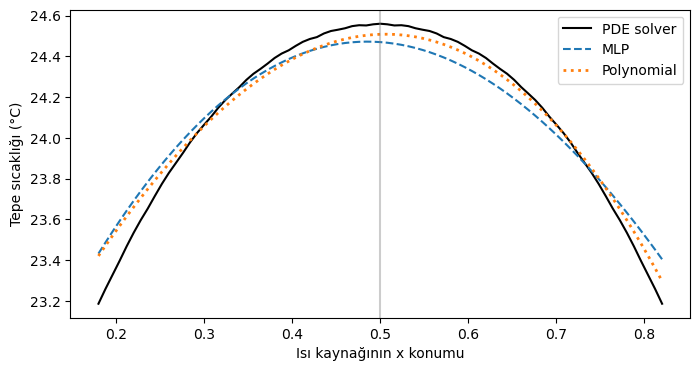

In [13]:
# Kaynağın x konumu 0.18'den 0.82'ye kadar değişsin.
x_positions = np.linspace(0.18, 0.82, 81)

# Her satır [kaynak x, kaynak y, şiddet, iletkenlik, kenar sıcaklığı].
# Yalnızca ilk değer değişiyor.
slice_designs = np.array([
    [xs, 0.50, 180.0, 1.0, 20.0]
    for xs in x_positions
])

# Her tasarım için PDE solver ile referans tepe sıcaklığını hesapla.
slice_solver = np.array([
    solve_temperature(*design).max()
    for design in slice_designs
])

# Modeller girdileri eğitimde kullandığımız 0–1 ölçeğinde bekliyor.
slice_scaled = (slice_designs - lower) / (upper - lower)

# Eğitilmiş MLP ile 81 tahmin yap ve sıcaklık ölçeğine dön.
with torch.no_grad():
    slice_tensor = torch.tensor(slice_scaled, dtype=torch.float32)
    slice_mlp = model(slice_tensor).squeeze(1).numpy() * y_std + y_mean

# Polinom tahminleri zaten sıcaklık ölçeğinde.
slice_poly = polynomial.predict(slice_scaled)

# Üç eğriyi aynı eksende çiz.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_positions, slice_solver, color="black", label="PDE solver")
ax.plot(x_positions, slice_mlp, "--", label="MLP")
ax.plot(x_positions, slice_poly, ":", linewidth=2, label="Polynomial")
ax.axvline(0.50, color="gray", alpha=0.4)
ax.set(xlabel="Isı kaynağının x konumu", ylabel="Tepe sıcaklığı (°C)")
ax.legend()
plt.show()

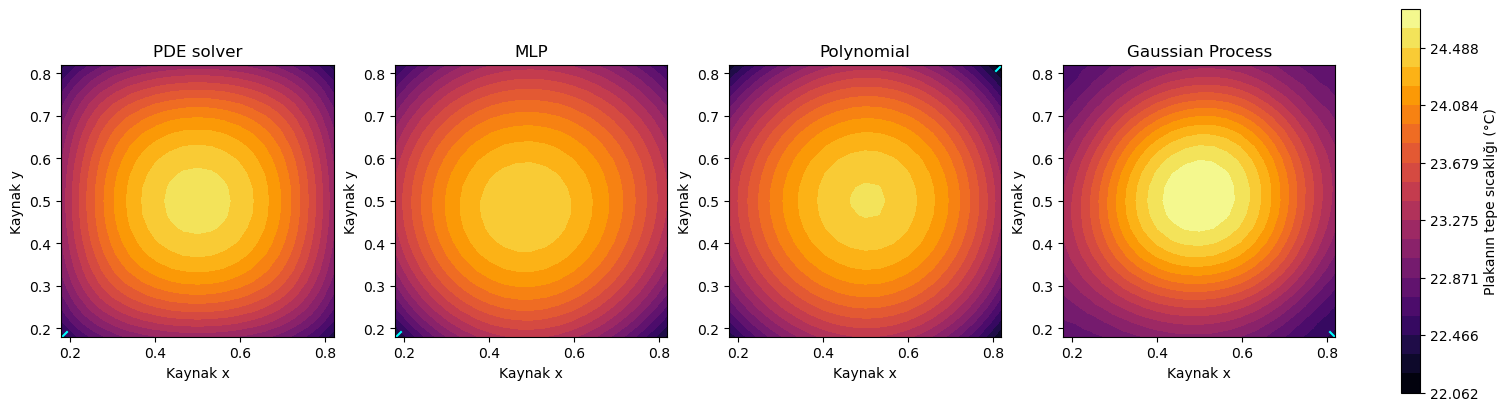

GP'nin seçtiği konum: [0.82 0.18]
Bu konumun PDE sonucu: 22.394 °C
GP regret: 0.000 °C


In [14]:
# GP'ye diğer modellerle aynı 441 normalize tasarımı ver.
# Çıktı doğrudan sıcaklık ölçeğinde.
gp_peaks = gp.predict(scaled_candidates)

# GP'nin en düşük tepe sıcaklığını tahmin ettiği adayı bul.
gp_chosen = gp_peaks.argmin()

# Dört panelde aynı sıcaklık aynı renkte görünsün.
all_peaks = np.concatenate([solver_peaks, predicted_peaks, poly_peaks, gp_peaks])
levels = np.linspace(all_peaks.min(), all_peaks.max(), 21)

fig, axes = plt.subplots(1, 4, figsize=(15, 4), layout="constrained")

for ax, title, peaks, selected in zip(
    axes,
    ["PDE solver", "MLP", "Polynomial", "Gaussian Process"],
    [solver_peaks, predicted_peaks, poly_peaks, gp_peaks],
    [best, chosen, poly_chosen, gp_chosen],
):
    # Her kaynak konumunu, o tasarımın tepe sıcaklığıyla renklendir.
    colors = ax.tricontourf(
        candidates[:, 0], candidates[:, 1], peaks,
        levels=levels, cmap="inferno",
    )

    # Camgöbeği ×, bu panelin seçtiği konumu gösterir.
    ax.scatter(*candidates[selected, :2], marker="x", color="cyan", s=80)
    ax.set(title=title, xlabel="Kaynak x", ylabel="Kaynak y", aspect="equal")

fig.colorbar(colors, ax=axes, label="Plakanın tepe sıcaklığı (°C)")
plt.show()

# GP'nin kararını, aynı konumun önceden hesaplanmış PDE sonucuyla değerlendir.
gp_regret = solver_peaks[gp_chosen] - solver_peaks[best]
print("GP'nin seçtiği konum:", candidates[gp_chosen, :2])
print(f"Bu konumun PDE sonucu: {solver_peaks[gp_chosen]:.3f} °C")
print(f"GP regret: {gp_regret:.3f} °C")

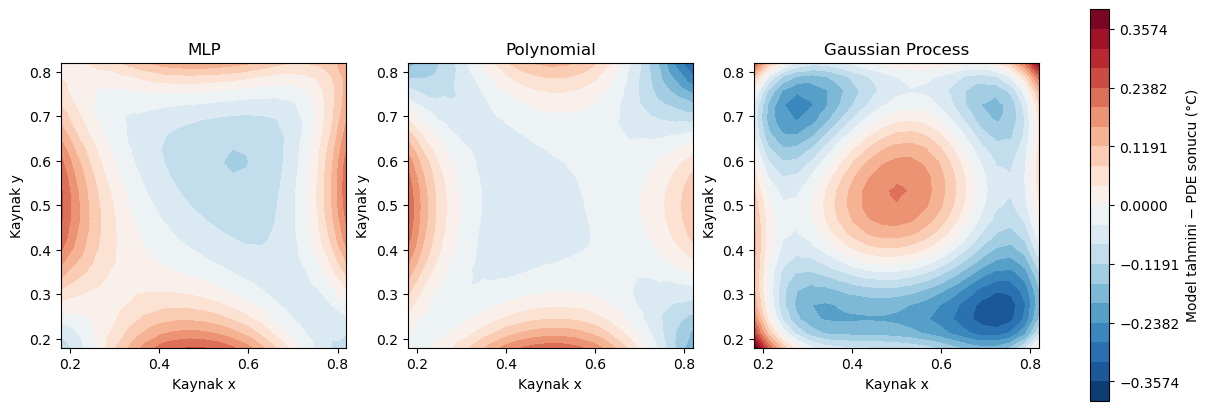

In [15]:
# Pozitif fark: model fazla sıcak tahmin etti.
# Negatif fark: model daha düşük sıcaklık tahmin etti.
errors = {
    "MLP": predicted_peaks - solver_peaks,
    "Polynomial": poly_peaks - solver_peaks,
    "Gaussian Process": gp_peaks - solver_peaks,
}

# Üç haritada da aynı hata aynı renkte görünsün.
limit = max(np.abs(error).max() for error in errors.values())
error_levels = np.linspace(-limit, limit, 21)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")

for ax, (name, error) in zip(axes, errors.items()):
    colors = ax.tricontourf(
        candidates[:, 0], candidates[:, 1], error,
        levels=error_levels, cmap="RdBu_r",
    )
    ax.set(title=name, xlabel="Kaynak x", ylabel="Kaynak y", aspect="equal")

fig.colorbar(colors, ax=axes, label="Model tahmini − PDE sonucu (°C)")
plt.show()

In [16]:
# (0.50, 0.50) konumuna en yakın adayın satırını bul.
center = np.argmin(np.sum((candidates[:, :2] - [0.50, 0.50])**2, axis=1))

# Aynı tasarım için PDE referansını ve üç modelin işaretli hatasını yazdır.
print(f"Merkezde PDE sonucu: {solver_peaks[center]:.3f} °C")
for name, error in errors.items():
    print(f"{name:16s} | tahmin − PDE = {error[center]:+.3f} °C")

Merkezde PDE sonucu: 24.560 °C
MLP              | tahmin − PDE = -0.090 °C
Polynomial       | tahmin − PDE = -0.052 °C
Gaussian Process | tahmin − PDE = +0.197 °C


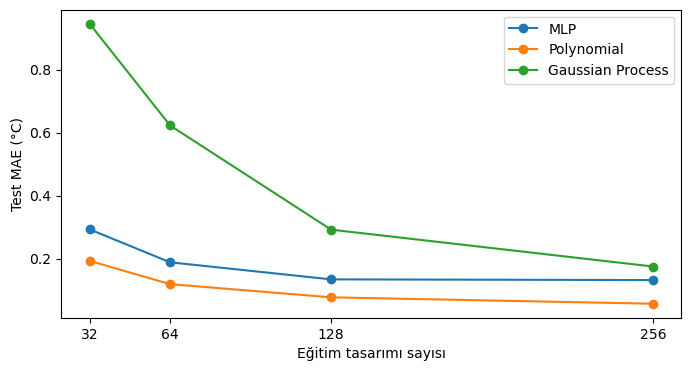

In [17]:
from sklearn.base import clone  # Aynı ayarlarla yeni, eğitilmemiş model kurar.

# 256 örnekli modelleri zaten eğittik. Küçük bütçeleri şimdi deniyoruz.
budgets = [32, 64, 128]
scores = {"MLP": [], "Polynomial": [], "Gaussian Process": []}

for count in budgets:
    # Girdi ve hedef dizilerinden aynı ilk count tasarımı al.
    x_subset = X_train[:count]
    y_subset = y_train[:count]

    # Önceden eğittiğimiz polinom ve GP'nin ayarlarını aynen kullan.
    for name, template in [("Polynomial", polynomial), ("Gaussian Process", gp)]:
        small_model = clone(template)
        small_model.fit(x_subset, y_subset)
        test_predictions = small_model.predict(X_test)
        scores[name].append(np.abs(test_predictions - y_test).mean())

    # Her bütçede MLP aynı başlangıç ağırlıklarından başlasın.
    torch.manual_seed(42)
    small_mlp = nn.Sequential(
        nn.Linear(5, 48), nn.SiLU(),
        nn.Linear(48, 48), nn.SiLU(),
        nn.Linear(48, 1),
    )

    # Yalnızca bu eğitim alt kümesinin değerleriyle hedefi ölçekle.
    subset_mean = y_subset.mean()
    subset_std = y_subset.std()
    x_tensor = torch.tensor(x_subset, dtype=torch.float32)
    y_tensor = torch.tensor(
        ((y_subset - subset_mean) / subset_std)[:, None],
        dtype=torch.float32,
    )

    # Orijinal MLP ile aynı Adam ayarları ve 450 güncelleme.
    small_optimizer = torch.optim.Adam(small_mlp.parameters(), lr=0.004)
    for _ in range(450):
        small_optimizer.zero_grad()
        loss = loss_function(small_mlp(x_tensor), y_tensor)
        loss.backward()
        small_optimizer.step()

    # Eğitimde kullanılmayan 128 tasarımda tahmin yap.
    small_mlp.eval()
    with torch.no_grad():
        predictions = small_mlp(x_test_tensor).squeeze(1).numpy()
    predictions = predictions * subset_std + subset_mean
    scores["MLP"].append(np.abs(predictions - y_test).mean())

# 256 tasarımla daha önce ölçtüğümüz sonuçları son nokta olarak ekle.
all_budgets = [*budgets, len(X_train)]
scores["MLP"].append(mae)
scores["Polynomial"].append(poly_errors.mean())
scores["Gaussian Process"].append(gp_errors.mean())

fig, ax = plt.subplots(figsize=(8, 4))
for name, values in scores.items():
    ax.plot(all_budgets, values, marker="o", label=name)

ax.set(xlabel="Eğitim tasarımı sayısı", ylabel="Test MAE (°C)")
ax.set_xticks(all_budgets)
ax.legend()
plt.show()

In [18]:
from time import perf_counter

def median_ms(run):
    run()  # İlk çağrıyı ısınma için yap.
    times = []
    for _ in range(7):
        start = perf_counter()
        run()
        times.append(1000 * (perf_counter() - start))
    return np.median(times)  # 7 ölçümün ortanca süresi, milisaniye.

def mlp_batch():
    # 441 tahmini tek çağrıda al ve sıcaklık ölçeğine çevir.
    with torch.no_grad():
        predictions = model(candidate_tensor).squeeze(1).numpy()
    return predictions * y_std + y_mean

# Her yöntem aynı 441 aday için tepe sıcaklığı üretiyor.
queries = {
    "PDE solver": lambda: [solve_temperature(*p).max() for p in candidates],
    "Polynomial": lambda: polynomial.predict(scaled_candidates),
    "MLP": mlp_batch,
    "Gaussian Process": lambda: gp.predict(scaled_candidates),
}

times = {name: median_ms(run) for name, run in queries.items()}

for name, ms in times.items():
    speedup = times["PDE solver"] / ms
    print(f"{name:16s} | {ms:8.3f} ms | {speedup:7.2f}×")

PDE solver       |   38.746 ms |    1.00×
Polynomial       |    0.110 ms |  352.91×
MLP              |    0.078 ms |  496.22×
Gaussian Process |    2.386 ms |   16.24×


In [19]:
import warnings
from sklearn.gaussian_process.kernels import ConstantKernel as C, Matern
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process.kernels import ConstantKernel as C
from sklearn.gaussian_process import GaussianProcessRegressor


# Aynı Matérn kernel, ama artık her girdi için ayrı length_scale var (ARD).
kernel_ard = C(1.0) * Matern(
    length_scale=[0.5] * 5,            # 5 girdi için başlangıç değerleri
    length_scale_bounds=(1e-2, 1e3),   # etkisiz girdiler çok büyük length_scale ister, üst sınırı geniş tut
    nu=2.5,
)

gp_ard = GaussianProcessRegressor(
    kernel=kernel_ard,
    alpha=1e-6,               # solver deterministik, bu yüzden çok küçük noise
    normalize_y=True,
    n_restarts_optimizer=3,   # farklı başlangıçlardan dene, en iyisini al
    random_state=0,
)
gp_ard.fit(X_train, y_train)   # artık optimizer length_scale'leri öğreniyor

gp_ard_predictions = gp_ard.predict(X_test)
gp_ard_errors = np.abs(gp_ard_predictions - y_test)

print(f"MLP          | MAE = {mae:.3f} | Max = {absolute_errors.max():.3f}")
print(f"Polynomial   | MAE = {poly_errors.mean():.3f} | Max = {poly_errors.max():.3f}")
print(f"GP (sabit)   | MAE = {gp_errors.mean():.3f} | Max = {gp_errors.max():.3f}")
print(f"GP (ARD)     | MAE = {gp_ard_errors.mean():.3f} | Max = {gp_ard_errors.max():.3f}")

# Küçük length_scale: çıktı o girdiye hızlı tepki veriyor, yani girdi önemli.
# Çok büyük length_scale: çıktı o girdiye neredeyse düz (veya doğrusal) bağlı.
input_names = ["kaynak x", "kaynak y", "şiddet", "iletkenlik", "kenar sıcaklığı"]
print()
for name, length_scale in zip(input_names, gp_ard.kernel_.k2.length_scale):
    print(f"{name:16s} | length_scale = {length_scale:8.2f}")

sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


MLP          | MAE = 0.132 | Max = 0.771
Polynomial   | MAE = 0.057 | Max = 0.275
GP (sabit)   | MAE = 0.175 | Max = 1.074
GP (ARD)     | MAE = 0.006 | Max = 0.068

kaynak x         | length_scale =    21.77
kaynak y         | length_scale =    21.68
şiddet           | length_scale =    53.69
iletkenlik       | length_scale =    27.23
kenar sıcaklığı  | length_scale =   501.71


sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [21]:
from scipy.stats import spearmanr

gp_ard_peaks = gp_ard.predict(scaled_candidates)

all_models = {
    "MLP":        predicted_peaks,
    "Polynomial": poly_peaks,
    "GP (sabit)": gp_peaks,
    "GP (ARD)":   gp_ard_peaks,
}

top_k = 20
true_top = set(np.argsort(solver_peaks)[:top_k])   # solver'a göre en soğuk 20 aday

for name, peaks in all_models.items():
    # Spearman: iki sıralama ne kadar aynı? (1.0 = mükemmel)
    rho = spearmanr(peaks, solver_peaks).statistic
    # Modelin en soğuk dediği 20 adayın kaçı gerçekten en soğuk 20 içinde?
    overlap = len(true_top & set(np.argsort(peaks)[:top_k]))
    print(f"{name:12s} | Spearman = {rho:.4f} | top-{top_k} örtüşme = {overlap}/{top_k}")

MLP          | Spearman = 0.9917 | top-20 örtüşme = 18/20
Polynomial   | Spearman = 0.9934 | top-20 örtüşme = 17/20
GP (sabit)   | Spearman = 0.9874 | top-20 örtüşme = 12/20
GP (ARD)     | Spearman = 0.9998 | top-20 örtüşme = 20/20


In [22]:
# Güvenlik limiti: tepe sıcaklık bu değeri aşmamalı.
T_limit = 26.0

# 5 boyutlu tasarım uzayında 2**12 = 4096 yeni tasarım. Hepsini solver ile çöz (gerçek cevap).
pool_unit = qmc.Sobol(d=5, scramble=True, seed=7).random_base2(m=12)
pool_parameters = qmc.scale(pool_unit, lower, upper)
pool_truth = np.array([solve_temperature(*p).max() for p in pool_parameters])
is_safe = pool_truth <= T_limit
print(f"Havuzda gerçekten güvenli tasarım oranı: {is_safe.mean():.1%}\n")

gp_mean, gp_std = gp_ard.predict(pool_unit, return_std=True)

# Her kural bir tasarıma "güvenli" diyor mu?
rules = {
    "Polynomial":    polynomial.predict(pool_unit) <= T_limit,
    "GP (sabit)":    gp.predict(pool_unit) <= T_limit,
    "GP (ARD)":      gp_mean <= T_limit,
    "GP (ARD) +2σ":  gp_mean + 2 * gp_std <= T_limit,   # belirsizlik payı bırak
}

for name, says_safe in rules.items():
    false_safe  = says_safe & ~is_safe    # "güvenli" dedi ama limit aşılıyor (tehlikeli)
    false_alarm = ~says_safe & is_safe    # "güvensiz" dedi ama aslında güvenli (maliyetli)
    worst = (pool_truth[false_safe] - T_limit).max() if false_safe.any() else 0.0
    print(f"{name:14s} | yanlış güvenli = {false_safe.sum():3d} "
          f"(en kötü aşım {worst:.3f} °C) | yanlış alarm = {false_alarm.sum():3d}")

Havuzda gerçekten güvenli tasarım oranı: 50.1%

Polynomial     | yanlış güvenli =   4 (en kötü aşım 0.096 °C) | yanlış alarm =  11
GP (sabit)     | yanlış güvenli =  14 (en kötü aşım 0.243 °C) | yanlış alarm =  15
GP (ARD)       | yanlış güvenli =   0 (en kötü aşım 0.000 °C) | yanlış alarm =   0
GP (ARD) +2σ   | yanlış güvenli =   0 (en kötü aşım 0.000 °C) | yanlış alarm =   8


sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bou

GP (ARD)     | MAE = 0.0064 | Max = 0.0676
GP (fizik)   | MAE = 0.0042 | Max = 0.0329


sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max

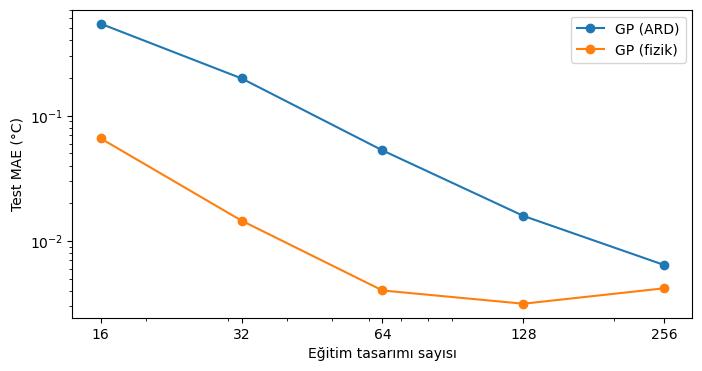

In [23]:
def physics_features(P):
    # P sütunları: x, y, şiddet, iletkenlik, kenar sıcaklığı
    return np.column_stack([P[:, 0], P[:, 1], np.log(P[:, 2] / P[:, 3]), P[:, 4]])

def fit_physics_gp(parameters, peaks):
    features = physics_features(parameters)
    mu, sd = features.mean(axis=0), features.std(axis=0)
    target = np.log(peaks - parameters[:, 4])          # log(sıcaklık artışı)
    model_gp = GaussianProcessRegressor(
        kernel=C(1.0) * Matern(length_scale=[1.0] * 4, length_scale_bounds=(1e-2, 1e3), nu=2.5),
        alpha=1e-8, normalize_y=True, n_restarts_optimizer=3, random_state=0,
    ).fit((features - mu) / sd, target)

    def predict(new_parameters):
        z = (physics_features(new_parameters) - mu) / sd
        return new_parameters[:, 4] + np.exp(model_gp.predict(z))   # sıcaklığa geri dön
    return predict

physics_predict = fit_physics_gp(train_parameters, y_train)
physics_errors = np.abs(physics_predict(test_parameters) - y_test)

print(f"GP (ARD)     | MAE = {gp_ard_errors.mean():.4f} | Max = {gp_ard_errors.max():.4f}")
print(f"GP (fizik)   | MAE = {physics_errors.mean():.4f} | Max = {physics_errors.max():.4f}")

# Learning curve: aynı bütçelerde iki GP'yi karşılaştır.
curve_budgets = [16, 32, 64, 128, 256]
curve = {"GP (ARD)": [], "GP (fizik)": []}
for count in curve_budgets:
    sub_unit, sub_params, sub_y = X_train[:count], train_parameters[:count], y_train[:count]
    small_ard = clone(gp_ard).fit(sub_unit, sub_y)
    curve["GP (ARD)"].append(np.abs(small_ard.predict(X_test) - y_test).mean())
    small_physics = fit_physics_gp(sub_params, sub_y)
    curve["GP (fizik)"].append(np.abs(small_physics(test_parameters) - y_test).mean())

fig, ax = plt.subplots(figsize=(8, 4))
for name, values in curve.items():
    ax.plot(curve_budgets, values, marker="o", label=name)
ax.set(xscale="log", yscale="log", xlabel="Eğitim tasarımı sayısı", ylabel="Test MAE (°C)")
ax.set_xticks(curve_budgets)
ax.set_xticklabels(curve_budgets)
ax.legend()
plt.show()